In [3]:
# Cài đặt TẤT CẢ thư viện cần thiết
!pip install --upgrade ultralytics -q
!pip install opencv-python pillow scikit-learn pyyaml tqdm matplotlib -q

You should consider upgrading via the 'C:\Users\K0HEI\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.
You should consider upgrading via the 'C:\Users\K0HEI\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


## Gộp dataset

In [54]:
import os
import shutil
import random
import hashlib
from glob import glob
from tqdm import tqdm

# =============================================================================
# CELL: GỘP 3 BỘ DATASET, LỌC TRÙNG (DEDUPLICATE) VÀ CHIA TỶ LỆ (70-20-10)
# =============================================================================

print("="*80)
print("PIPELINE: GỘP - CHUẨN HÓA - LỌC TRÙNG - CHIA DATASET")
print("="*80)

# ---------------------------------------------------------
# 1. CẤU HÌNH ĐƯỜNG DẪN (Bạn hãy trỏ lại cho đúng với máy)
# ---------------------------------------------------------
DS_2_CLASSES_PATH = r"D:\Barcodes"               # Bộ 1: Barcode & QR Code
DS_1_CLASS_PATH = r"D:\qrcode"                   # Bộ 2: Chỉ QR Code (bộ cũ)
DS_3_NEW_QR_PATH = r"D:\QRcode2"              # Bộ 3: Chỉ QR Code (bộ mới thêm)

OUTPUT_DATASET_PATH = r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection" # Thư mục đích

# ---------------------------------------------------------
# 2. CẤU HÌNH MAP CLASS ID 
# MỤC TIÊU: 0 = Barcode, 1 = QR Code
# ---------------------------------------------------------
TARGET_CLASSES = ['Barcode', 'QR Code']

# Bộ 1: ['bar_code', 'barcode', 'detection', 'qr_code'] -> (0, 1, 2, 3)
MAPPING_DS_1 = {
    '0': '0',  # bar_code -> Barcode (0)
    '1': '0',  # barcode  -> Barcode (0)
    '2': '-1', # detection -> Xóa/Bỏ qua
    '3': '1',  # qr_code  -> QR Code (1)
}

# Bộ 2: ['QR_CODE', 'qr_code', 'qrcode'] -> (0, 1, 2)
MAPPING_DS_2 = {
    '0': '1',  # -> QR Code (1)
    '1': '1',  # -> QR Code (1)
    '2': '1',  # -> QR Code (1)
}

# Bộ 3: ['QR'] -> (Thường gán là 0 trong YOLO nếu chỉ có 1 class)
MAPPING_DS_3 = {
    '0': '1',  # -> QR Code (1)
    '1': '1',  # Dự phòng nếu file txt của bạn có cả id 1
}

# ---------------------------------------------------------
# 3. HÀM TÍNH MÃ HASH ĐỂ KIỂM TRA ẢNH TRÙNG NHAU (DEDUPLICATE)
# ---------------------------------------------------------
def get_file_hash(filepath):
    """Đọc file ảnh và tạo mã băm MD5 để so sánh nội dung."""
    hasher = hashlib.md5()
    try:
        with open(filepath, 'rb') as f:
            buf = f.read()
            hasher.update(buf)
        return hasher.hexdigest()
    except:
        return None

# ---------------------------------------------------------
# 4. HÀM QUÉT VÀ ĐỌC DỮ LIỆU LÊN RAM (CHƯA COPY)
# ---------------------------------------------------------
seen_hashes = set()       # Tập hợp lưu các mã hash đã gặp
valid_data_list = []      # Danh sách chứa toàn bộ thông tin ảnh hợp lệ
duplicate_count = 0

def collect_dataset(source_path, mapping_dict, prefix_name):
    global duplicate_count
    print(f"\n📂 Đang quét: {source_path}")
    
    if not os.path.exists(source_path):
        print(f"❌ KHÔNG TÌM THẤY THƯ MỤC: {source_path}")
        return
        
    image_files = glob(os.path.join(source_path, '**', '*.jpg'), recursive=True) + \
                  glob(os.path.join(source_path, '**', '*.png'), recursive=True) + \
                  glob(os.path.join(source_path, '**', '*.jpeg'), recursive=True)
                  
    for img_path in tqdm(image_files, desc=f"Xử lý {prefix_name}"):
        # Kiểm tra file ảnh có bị trùng nội dung không
        img_hash = get_file_hash(img_path)
        if img_hash in seen_hashes:
            duplicate_count += 1
            continue  # Bỏ qua luôn ảnh này vì nội dung đã tồn tại
            
        # Tìm file label
        label_path = img_path.rsplit('.', 1)[0] + '.txt'
        label_path_alt = img_path.replace('images', 'labels').rsplit('.', 1)[0] + '.txt'
        
        actual_label_path = next((p for p in [label_path, label_path_alt] if os.path.exists(p)), None)
        if not actual_label_path:
            continue
            
        # Đọc và convert label
        new_lines = []
        with open(actual_label_path, 'r') as f:
            lines = f.readlines()
            
        for line in lines:
            parts = line.strip().split()
            if len(parts) >= 5:
                old_id = parts[0]
                if old_id in mapping_dict:
                    new_id = mapping_dict[old_id]
                    if new_id != '-1':
                        new_lines.append(f"{new_id} {' '.join(parts[1:])}\n")
        
        # Nếu ảnh có object sau khi chuyển đổi, đưa vào danh sách tổng
        if len(new_lines) > 0:
            seen_hashes.add(img_hash)
            valid_data_list.append({
                'src_img': img_path,
                'prefix': prefix_name,
                'filename': os.path.basename(img_path),
                'lines': new_lines
            })

# Thu thập toàn bộ dữ liệu từ 3 nguồn
collect_dataset(DS_2_CLASSES_PATH, MAPPING_DS_1, "DS1")
collect_dataset(DS_1_CLASS_PATH, MAPPING_DS_2, "DS2")
collect_dataset(DS_3_NEW_QR_PATH, MAPPING_DS_3, "DS3")

print(f"\n✅ Đã quét xong. Tổng ảnh hợp lệ: {len(valid_data_list)}")
print(f"🗑️ Đã tự động loại bỏ {duplicate_count} ảnh trùng lặp (trùng nội dung ảnh).")

# ---------------------------------------------------------
# 5. DỌN SẠCH THƯ MỤC CŨ VÀ TẠO MỚI (CHỐNG RÒ RỈ DỮ LIỆU)
# ---------------------------------------------------------
print("\n🧹 Đang dọn dẹp thư mục đích cũ...")
for split in ['train', 'val', 'test']:
    split_img_dir = os.path.join(OUTPUT_DATASET_PATH, split, 'images')
    split_lbl_dir = os.path.join(OUTPUT_DATASET_PATH, split, 'labels')
    
    # Xóa sạch nếu tồn tại
    if os.path.exists(split_img_dir): shutil.rmtree(split_img_dir)
    if os.path.exists(split_lbl_dir): shutil.rmtree(split_lbl_dir)
    
    # Tạo lại thư mục trống
    os.makedirs(split_img_dir, exist_ok=True)
    os.makedirs(split_lbl_dir, exist_ok=True)

# ---------------------------------------------------------
# 6. SHUFFLE VÀ CHIA TỶ LỆ 70 - 20 - 10
# ---------------------------------------------------------
random.seed(42)
random.shuffle(valid_data_list)

total = len(valid_data_list)
train_size = int(total * 0.7)
val_size = int(total * 0.2)

splits = {
    'train': valid_data_list[:train_size],
    'val': valid_data_list[train_size:train_size + val_size],
    'test': valid_data_list[train_size + val_size:]
}

print(f"\n📊 PHÂN CHIA (70-20-10):")
for k, v in splits.items():
    print(f"  🟢 {k.upper()}: {len(v)} ảnh")

# ---------------------------------------------------------
# 7. TIẾN HÀNH COPY FILE VÀ GHI NHÃN
# ---------------------------------------------------------
for split_name, data_list in splits.items():
    if not data_list: continue
    print(f"\n📁 Đang copy và lưu vào {split_name.upper()}...")
    
    for item in tqdm(data_list):
        new_img_name = f"{item['prefix']}_{item['filename']}"
        base_name = os.path.splitext(item['filename'])[0]
        new_lbl_name = f"{item['prefix']}_{base_name}.txt"
        
        dst_img = os.path.join(OUTPUT_DATASET_PATH, split_name, 'images', new_img_name)
        dst_lbl = os.path.join(OUTPUT_DATASET_PATH, split_name, 'labels', new_lbl_name)
        
        # Copy file ảnh
        shutil.copy2(item['src_img'], dst_img)
        # Ghi file txt đã được chuyển đổi ID
        with open(dst_lbl, 'w') as f:
            f.writelines(item['lines'])

# ---------------------------------------------------------
# 8. TẠO FILE DATA.YAML
# ---------------------------------------------------------
yaml_content = f"""path: {OUTPUT_DATASET_PATH}
train: train/images
val: val/images
test: test/images

nc: 2
names: {TARGET_CLASSES}
"""
with open(os.path.join(OUTPUT_DATASET_PATH, 'data.yaml'), 'w') as f:
    f.write(yaml_content)

print(f"\n{'='*80}")
print("🎉 HOÀN TẤT TẤT CẢ QUY TRÌNH!")
print(f"   Vị trí dataset mới chuẩn YOLO: {OUTPUT_DATASET_PATH}")
print(f"{'='*80}")

PIPELINE: GỘP - CHUẨN HÓA - LỌC TRÙNG - CHIA DATASET

📂 Đang quét: D:\Barcodes


Xử lý DS1: 100%|██████████| 9988/9988 [00:07<00:00, 1415.04it/s]



📂 Đang quét: D:\qrcode


Xử lý DS2: 100%|██████████| 1547/1547 [00:00<00:00, 4509.55it/s]



📂 Đang quét: D:\QRcode2


...


📁 Đang copy và lưu vào VAL...


100%|██████████| 2861/2861 [00:01<00:00, 1708.62it/s]



📁 Đang copy và lưu vào TEST...


100%|██████████| 1431/1431 [00:00<00:00, 1701.16it/s]


🎉 HOÀN TẤT TẤT CẢ QUY TRÌNH!
   Vị trí dataset mới chuẩn YOLO: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection


## Import thư viện

In [1]:
"""
=============================================================================
PIPELINE HOÀN CHỈNH: OBJECT DETECTION VỚI YOLOV8
=============================================================================
"""

# =============================================================================
# PHẦN 1: CÀI ĐẶT THƯ VIỆN
# =============================================================================

print("="*80)
print("BƯỚC 1: CÀI ĐẶT THƯ VIỆN")
print("="*80)

print("\n⏳ Đang import thư viện...")

import os
import shutil
import random
import yaml
from pathlib import Path
from sklearn.model_selection import train_test_split
import cv2
from PIL import Image
import numpy as np
from ultralytics import YOLO
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from glob import glob
from tqdm import tqdm

# Kiểm tra GPU
print(f"\n✓ CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"✓ GPU Device: {torch.cuda.get_device_name(0)}")
    print(f"✓ VRAM: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")
else:
    print("⚠️  Đang sử dụng CPU - Training sẽ chậm!")

print("\n✓ Đã cài đặt xong tất cả thư viện!")

BƯỚC 1: CÀI ĐẶT THƯ VIỆN

⏳ Đang import thư viện...

✓ CUDA available: True
✓ GPU Device: NVIDIA GeForce RTX 2060 SUPER
✓ VRAM: 8.00 GB

✓ Đã cài đặt xong tất cả thư viện!


## Cấu hình cơ bản

In [73]:
# =============================================================================
# CELL 2: CẤU HÌNH - THAY ĐỔI PHẦN NÀY
# =============================================================================

print("="*80)
print("CELL 2: CẤU HÌNH")
print("="*80)

# ==================== THAY ĐỔI CẤU HÌNH Ở ĐÂY ====================

# ĐƯỜNG DẪN DATASET
ORIGINAL_DATASET_PATH = r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection"              # ← Dataset gốc
OUTPUT_DATASET_PATH = r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection"         # ← Dataset sau khi chia lại

# TỶ LỆ CHIA DATASET
TRAIN_RATIO = 0.7   # 70% train
VAL_RATIO = 0.2     # 20% validation  
TEST_RATIO = 0.1    # 10% test

# CẤU HÌNH TRAINING
MODEL_NAME = 'yolov11n.pt'   
EPOCHS = 100
BATCH_SIZE = 8
IMG_SIZE = 640
DEVICE = '0'                 # '0' = GPU, 'cpu' = CPU
PROJECT_NAME = 'runs/detect'
EXPERIMENT_NAME = 'yolov11_barcode_qr_training'

# CLASS NAMES 
MANUAL_CLASS_NAMES = ['Barcode', 'QR Code']

# =================================================================

print(f"\n✓ Dataset gốc: {ORIGINAL_DATASET_PATH}")
print(f"✓ Dataset mới: {OUTPUT_DATASET_PATH}")
print(f"✓ Tỷ lệ: {TRAIN_RATIO*100:.0f}% | {VAL_RATIO*100:.0f}% | {TEST_RATIO*100:.0f}%")
print(f"✓ Model: {MODEL_NAME}")
print(f"✓ Epochs: {EPOCHS}")

print("\n✅ Cấu hình hoàn tất!")

CELL 2: CẤU HÌNH

✓ Dataset gốc: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection
✓ Dataset mới: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection
✓ Tỷ lệ: 70% | 20% | 10%
✓ Model: yolov11n.pt
✓ Epochs: 100

✅ Cấu hình hoàn tất!


## Gộp ảnh

In [15]:
# =============================================================================
# CELL 3: GỘP TẤT CẢ ẢNH TỪ TRAIN/VAL/TEST
# =============================================================================

print("="*80)
print("CELL 3: GỘP TẤT CẢ ẢNH")
print("="*80)

# Tạo thư mục tạm
temp_dir = os.path.join(OUTPUT_DATASET_PATH, '_temp')
temp_images_dir = os.path.join(temp_dir, 'all_images')
temp_labels_dir = os.path.join(temp_dir, 'all_labels')

# Xóa nếu đã tồn tại
if os.path.exists(temp_images_dir):
    shutil.rmtree(temp_images_dir)
if os.path.exists(temp_labels_dir):
    shutil.rmtree(temp_labels_dir)

os.makedirs(temp_images_dir, exist_ok=True)
os.makedirs(temp_labels_dir, exist_ok=True)

# Gộp ảnh
image_counter = 0
stats = {}

possible_splits = ['train', 'training', 'valid', 'validation', 'val', 'test', 'testing']

print("\n🔄 Bắt đầu gộp ảnh...")

for split in possible_splits:
    img_dir = os.path.join(ORIGINAL_DATASET_PATH, split, 'images')
    lbl_dir = os.path.join(ORIGINAL_DATASET_PATH, split, 'labels')
    
    if not os.path.exists(img_dir):
        continue
    
    images = [f for f in os.listdir(img_dir) 
             if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
    
    if len(images) == 0:
        continue
    
    print(f"\n📂 {split.upper()}: {len(images)} ảnh")
    stats[split] = len(images)
    
    for img_name in tqdm(images, desc=f"  Copy {split}"):
        src_img = os.path.join(img_dir, img_name)
        label_name = os.path.splitext(img_name)[0] + '.txt'
        src_lbl = os.path.join(lbl_dir, label_name)
        
        # Tên mới
        ext = os.path.splitext(img_name)[1]
        new_img_name = f"image_{image_counter:06d}{ext}"
        new_lbl_name = f"image_{image_counter:06d}.txt"
        
        dst_img = os.path.join(temp_images_dir, new_img_name)
        dst_lbl = os.path.join(temp_labels_dir, new_lbl_name)
        
        # Copy
        shutil.copy2(src_img, dst_img)
        
        if os.path.exists(src_lbl):
            shutil.copy2(src_lbl, dst_lbl)
        
        image_counter += 1

# Thống kê
print(f"\n{'='*80}")
print("📊 THỐNG KÊ:")
print(f"{'='*80}")
for split, count in stats.items():
    print(f"  {split.upper():<12}: {count:>5} ảnh")
print(f"  {'TỔNG':<12}: {image_counter:>5} ảnh")
print(f"{'='*80}")

total_images = image_counter

print(f"\n✅ Đã gộp {total_images} ảnh!")
print(f"   📁 Images: {temp_images_dir}")
print(f"   📁 Labels: {temp_labels_dir}")

CELL 3: GỘP TẤT CẢ ẢNH

🔄 Bắt đầu gộp ảnh...

📂 TRAIN: 7174 ảnh


  Copy train: 100%|██████████| 7174/7174 [00:41<00:00, 173.87it/s]



📂 VALID: 2382 ảnh


  Copy valid: 100%|██████████| 2382/2382 [00:13<00:00, 181.20it/s]



📂 TEST: 432 ảnh


  Copy test: 100%|██████████| 432/432 [00:02<00:00, 173.49it/s]


📊 THỐNG KÊ:
  TRAIN       :  7174 ảnh
  VALID       :  2382 ảnh
  TEST        :   432 ảnh
  TỔNG        :  9988 ảnh

✅ Đã gộp 9988 ảnh!
   📁 Images: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\_temp\all_images
   📁 Labels: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\_temp\all_labels


## Chia ảnh

In [ ]:
# =============================================================================
# CELL 4: CHIA LẠI DATASET THEO TỶ LỆ
# =============================================================================

print("="*80)
print("CELL 4: CHIA DATASET THEO TỶ LỆ")
print("="*80)

# Kiểm tra tỷ lệ
total_ratio = TRAIN_RATIO + VAL_RATIO + TEST_RATIO
if abs(total_ratio - 1.0) > 0.001:
    print(f"❌ Lỗi: Tổng tỷ lệ = {total_ratio}, phải bằng 1.0!")
else:
    # Set seed
    random.seed(42)
    np.random.seed(42)
    
    # Tạo thư mục
    print("\n📁 Tạo cấu trúc thư mục...")
    for split in ['train', 'val', 'test']:
        os.makedirs(os.path.join(OUTPUT_DATASET_PATH, split, 'images'), exist_ok=True)
        os.makedirs(os.path.join(OUTPUT_DATASET_PATH, split, 'labels'), exist_ok=True)
    
    # Lấy danh sách ảnh
    all_images = [f for f in os.listdir(temp_images_dir) 
                  if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
    
    print(f"✓ Tổng: {len(all_images)} ảnh")
    
    # Shuffle
    random.shuffle(all_images)
    
    # Chia
    total = len(all_images)
    train_size = int(total * TRAIN_RATIO)
    val_size = int(total * VAL_RATIO)
    test_size = total - train_size - val_size
    
    train_images = all_images[:train_size]
    val_images = all_images[train_size:train_size + val_size]
    test_images = all_images[train_size + val_size:]
    
    print(f"\n{'='*80}")
    print("📊 PHÂN CHIA:")
    print(f"{'='*80}")
    print(f"  🟢 TRAIN: {len(train_images):>5} ảnh ({TRAIN_RATIO*100:.1f}%)")
    print(f"  🟡 VAL:   {len(val_images):>5} ảnh ({VAL_RATIO*100:.1f}%)")
    print(f"  🔴 TEST:  {len(test_images):>5} ảnh ({TEST_RATIO*100:.1f}%)")
    print(f"{'='*80}")
    
    # Copy files
    splits = {
        'train': train_images,
        'val': val_images,
        'test': test_images
    }
    
    for split_name, image_list in splits.items():
        if len(image_list) == 0:
            continue
        
        print(f"\n📁 Copy {split_name.upper()}...")
        
        for img_name in tqdm(image_list, desc=f"  {split_name}"):
            src_img = os.path.join(temp_images_dir, img_name)
            dst_img = os.path.join(OUTPUT_DATASET_PATH, split_name, 'images', img_name)
            shutil.copy2(src_img, dst_img)
            
            label_name = os.path.splitext(img_name)[0] + '.txt'
            src_lbl = os.path.join(temp_labels_dir, label_name)
            dst_lbl = os.path.join(OUTPUT_DATASET_PATH, split_name, 'labels', label_name)
            
            if os.path.exists(src_lbl):
                shutil.copy2(src_lbl, dst_lbl)
    
    # Xóa thư mục tạm
    if os.path.exists(temp_dir):
        shutil.rmtree(temp_dir)
        print(f"\n🗑️  Đã xóa thư mục tạm")
    
    print(f"\n✅ Chia dataset xong!")
    print(f"   📁 Dataset mới: {OUTPUT_DATASET_PATH}")

## Data.yaml

In [57]:
# =============================================================================
# CELL 5: TẠO FILE DATA.YAML
# =============================================================================

print("="*80)
print("CELL 5: TẠO DATA.YAML")
print("="*80)

# Lấy class names
if MANUAL_CLASS_NAMES is not None:
    class_names = MANUAL_CLASS_NAMES
    print(f"✓ Dùng class names thủ công: {class_names}")
else:
    # Đọc từ data.yaml gốc
    yaml_path_old = os.path.join(ORIGINAL_DATASET_PATH, 'data.yaml')
    
    if os.path.exists(yaml_path_old):
        with open(yaml_path_old, 'r', encoding='utf-8') as f:
            data_old = yaml.safe_load(f)
        class_names = data_old.get('names', [])
        print(f"✓ Đọc từ data.yaml gốc: {class_names}")
    else:
        print("❌ Không tìm thấy data.yaml gốc!")
        print("Vui lòng nhập class names thủ công ở CELL 2 (MANUAL_CLASS_NAMES)")
        class_names = None

if class_names:
    # Tạo data.yaml mới
    yaml_path = os.path.join(OUTPUT_DATASET_PATH, 'data.yaml')
    
    data = {
        'path': OUTPUT_DATASET_PATH,
        'train': 'train/images',
        'val': 'val/images',
        'test': 'test/images',
        'nc': len(class_names),
        'names': class_names
    }
    
    with open(yaml_path, 'w', encoding='utf-8') as f:
        yaml.dump(data, f, sort_keys=False, default_flow_style=False, allow_unicode=True)
    
    print(f"\n{'='*80}")
    print("📄 ĐÃ TẠO DATA.YAML")
    print(f"{'='*80}")
    print(f"  File: {yaml_path}")
    print(f"  Classes ({len(class_names)}): {class_names}")
    print(f"{'='*80}")
    
    print(f"\n✅ Tạo data.yaml thành công!")

CELL 5: TẠO DATA.YAML
✓ Dùng class names thủ công: ['Barcode', 'QR Code']

📄 ĐÃ TẠO DATA.YAML
  File: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\data.yaml
  Classes (2): ['Barcode', 'QR Code']

✅ Tạo data.yaml thành công!


## Kiểm tra 3 mẫu

CELL 6: VISUALIZE DATASET

📸 Hiển thị 3 mẫu ngẫu nhiên...


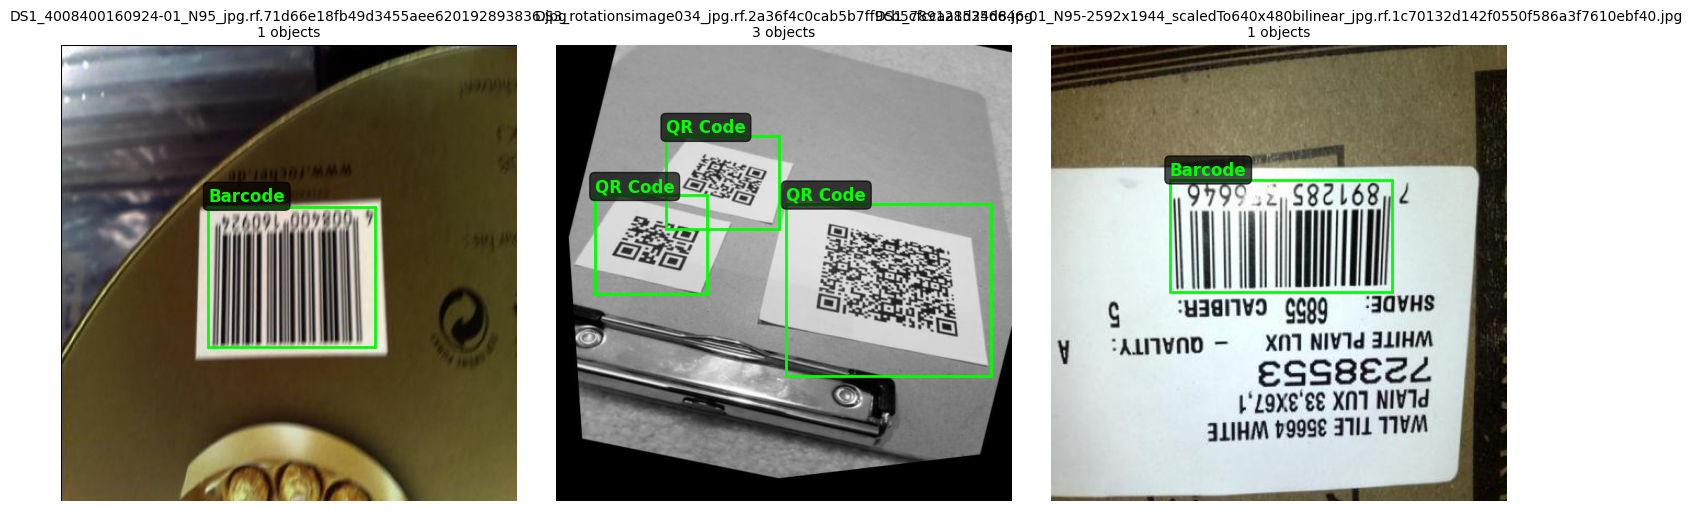


✅ Đã lưu preview: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\dataset_preview.jpg


In [66]:
# =============================================================================
# CELL 6: VISUALIZE DATASET
# =============================================================================

print("="*80)
print("CELL 6: VISUALIZE DATASET")
print("="*80)

print("\n📸 Hiển thị 3 mẫu ngẫu nhiên...")

train_images_dir = os.path.join(OUTPUT_DATASET_PATH, 'train', 'images')
train_labels_dir = os.path.join(OUTPUT_DATASET_PATH, 'train', 'labels')

if os.path.exists(train_images_dir):
    all_imgs = [f for f in os.listdir(train_images_dir) if f.endswith(('.jpg', '.png'))]
    if len(all_imgs) >= 3:
        sample_imgs = random.sample(all_imgs, 3)
        
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        
        for i, img_name in enumerate(sample_imgs):
            img_path = os.path.join(train_images_dir, img_name)
            label_name = os.path.splitext(img_name)[0] + '.txt'
            label_path = os.path.join(train_labels_dir, label_name)
            
            img = np.array(Image.open(img_path))
            h, w = img.shape[:2]
            
            ax = axes[i]
            ax.imshow(img)
            ax.axis('off')
            
            n_boxes = 0
            if os.path.exists(label_path):
                with open(label_path, 'r') as f:
                    for line in f:
                        parts = line.strip().split()
                        if len(parts) >= 5:
                            class_id = int(parts[0])
                            x_center, y_center, width, height = map(float, parts[1:5])
                            
                            x1 = int((x_center - width/2) * w)
                            y1 = int((y_center - height/2) * h)
                            box_w = int(width * w)
                            box_h = int(height * h)
                            
                            rect = patches.Rectangle((x1, y1), box_w, box_h, 
                                                   linewidth=2, edgecolor='lime', facecolor='none')
                            ax.add_patch(rect)
                            ax.text(x1, y1-5, f'{MANUAL_CLASS_NAMES[class_id]}', 
                                    color='lime', fontsize=12, weight='bold',
                                    bbox=dict(boxstyle='round', facecolor='black', alpha=0.7))
                            n_boxes += 1
            
            ax.set_title(f'{img_name}\n{n_boxes} objects', fontsize=10)
            
        plt.tight_layout()
        preview_path = os.path.join(OUTPUT_DATASET_PATH, 'dataset_preview.jpg')
        plt.savefig(preview_path, dpi=150, bbox_inches='tight')
        plt.show()
        
        print(f"\n✅ Đã lưu preview: {preview_path}")

## Thống kê số lớp

⏳ Đang quét dữ liệu từ các thư mục...

📊 THỐNG KÊ PHÂN BỐ ẢNH GIAO THÔNG (TỔNG HỢP 3 TẬP)
Tổng số file txt (ảnh) đã quét: 8722
  Tên lớp  Số lượng Ảnh  Tỷ lệ (%)
Motorbike          6954      42.33
      Car          6824      41.54
    Truck          1726      10.51
      Bus           766       4.66
     Bike           158       0.96


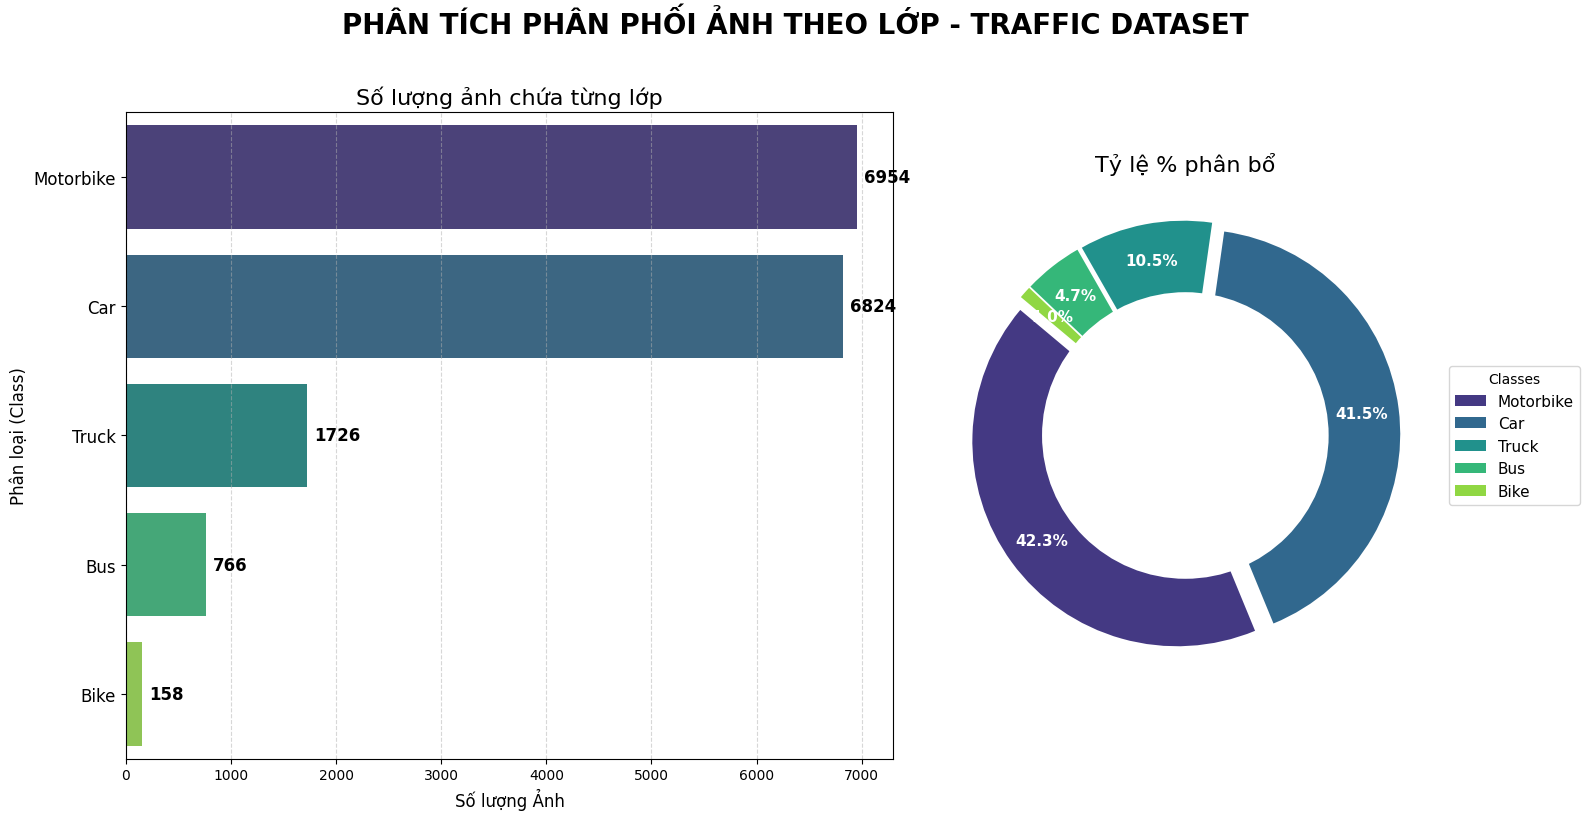

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. CẤU HÌNH ĐƯỜNG DẪN VÀ TÊN LỚP
# ==========================================
BASE_DIR = r"D:\Stuffs\ThiGiacMayTinh\DoAnTGMT\data"
FOLDERS = ['train', 'val', 'test'] 

class_list = ['Bike', 'Bus', 'Car', 'Motorbike', 'Truck']

CLASS_NAMES = {i: name for i, name in enumerate(class_list)}

def analyze_traffic_data(base_dir, folders):
    class_counts = []
    total_images_scanned = 0
    
    print("⏳ Đang quét dữ liệu từ các thư mục...")
    
    # Duyệt qua các thư mục train, val, test
    for folder in folders:
        # Truy cập đúng cấu trúc: data/labels/train
        labels_path = os.path.join(base_dir, 'labels', folder)
        
        if not os.path.exists(labels_path):
            print(f"⚠️ Bỏ qua: Không tìm thấy {labels_path}")
            continue

        label_files = [f for f in os.listdir(labels_path) if f.endswith('.txt') and f != 'classes.txt']
        total_images_scanned += len(label_files)
        
        for label_file in label_files:
            # Dùng SET để đếm số lượng ẢNH chứa class đó (Không đếm tổng số box)
            classes_in_image = set() 
            with open(os.path.join(labels_path, label_file), 'r') as f:
                for line in f:
                    parts = line.split()
                    if parts:
                        class_id = int(parts[0])
                        classes_in_image.add(CLASS_NAMES.get(class_id, f"ID_{class_id}"))
            
            # Đưa các class xuất hiện trong ảnh này vào mảng đếm
            class_counts.extend(list(classes_in_image))

    # ==========================================
    # 2. TẠO DATAFRAME THỐNG KÊ
    # ==========================================
    df = pd.DataFrame(class_counts, columns=['Tên lớp'])
    stats = df['Tên lớp'].value_counts().reset_index()
    stats.columns = ['Tên lớp', 'Số lượng Ảnh']
    
    # Đảm bảo hiển thị đủ 5 lớp (Kể cả lớp có 0 ảnh)
    all_classes_df = pd.DataFrame({'Tên lớp': class_list})
    stats = pd.merge(all_classes_df, stats, on='Tên lớp', how='left').fillna(0)
    stats['Số lượng Ảnh'] = stats['Số lượng Ảnh'].astype(int)
    
    # Sắp xếp giảm dần
    stats = stats.sort_values(by='Số lượng Ảnh', ascending=False)
    
    total_instances = stats['Số lượng Ảnh'].sum()
    stats['Tỷ lệ (%)'] = (stats['Số lượng Ảnh'] / total_instances * 100).round(2)
    
    # Hiển thị console
    print("\n" + "="*55)
    print(f"📊 THỐNG KÊ PHÂN BỐ ẢNH GIAO THÔNG (TỔNG HỢP {len(folders)} TẬP)")
    print(f"Tổng số file txt (ảnh) đã quét: {total_images_scanned}")
    print("="*55)
    print(stats.to_string(index=False))
    print("="*55)

    # ==========================================
    # 3. VẼ BIỂU ĐỒ
    # ==========================================
    # Chỉnh size vừa phải cho 5 class (16x8)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw={'width_ratios': [1.5, 1]})
    plt.suptitle("PHÂN TÍCH PHÂN PHỐI ẢNH THEO LỚP - TRAFFIC DATASET", fontsize=20, fontweight='bold', y=1.02)

    # Biểu đồ 1: Barplot
    # Thêm hue và legend=False để tránh cảnh báo của Seaborn phiên bản mới
    sns.barplot(data=stats, y='Tên lớp', x='Số lượng Ảnh', palette='viridis', ax=ax1, hue='Tên lớp', legend=False)
    
    # Gắn label (số lượng) vào đuôi từng cột
    for i in ax1.containers:
        ax1.bar_label(i, padding=5, fontsize=12, fontweight='bold')
        
    ax1.set_title("Số lượng ảnh chứa từng lớp", fontsize=16)
    ax1.set_xlabel("Số lượng Ảnh", fontsize=12)
    ax1.set_ylabel("Phân loại (Class)", fontsize=12)
    ax1.grid(axis='x', linestyle='--', alpha=0.5)
    ax1.tick_params(axis='y', labelsize=12)

    # Biểu đồ 2: Donut Chart
    colors = sns.color_palette('viridis', len(stats))
    
    # Hiển thị mọi tỷ lệ %
    def autopct_format(values):
        def my_format(pct):
            return f'{pct:.1f}%' if pct > 0 else ''
        return my_format(values)

    wedges, texts, autotexts = ax2.pie(
        stats['Số lượng Ảnh'], 
        autopct=autopct_format, 
        startangle=140, 
        colors=colors, 
        pctdistance=0.82,
        explode=[0.05] * len(stats) # Tách khe giữa các phần
    )
    
    # Format text trong Donut
    for autotext in autotexts:
        autotext.set_color('white')
        autotext.set_fontsize(11)
        autotext.set_fontweight('bold')

    # Đặt vòng tròn trắng ở giữa tạo hiệu ứng Donut
    centre_circle = plt.Circle((0,0), 0.70, fc='white')
    ax2.add_artist(centre_circle)
    ax2.set_title("Tỷ lệ % phân bổ", fontsize=16)
    
    # Chú thích
    ax2.legend(wedges, stats['Tên lớp'], title="Classes", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1), fontsize=11)

    plt.tight_layout()
    plt.show()

    return stats

# Chạy script
if __name__ == "__main__":
    stats_result = analyze_traffic_data(BASE_DIR, FOLDERS)

## Yolo11n

In [ ]:
import os
import shutil
from ultralytics import YOLO

# =============================================================================
# CELL 7: TRAINING YOLO11s - TỐI ƯU HÓA NHẬN DIỆN MÃ VẠCH/QR
# =============================================================================

print("="*80)
print("CELL 7: TRAINING YOLO11s (OPTIMIZED)")
print("="*80)

yaml_path = os.path.join(OUTPUT_DATASET_PATH, 'data.yaml')

# --- CẬP NHẬT CẤU HÌNH ---
MODEL_NAME = 'yolo11s.pt' # Chuyển sang bản Small để cân bằng Accuracy & FPS
EXPERIMENT_NAME = 'yolo11s_barcode_qr_optimized' 

# Tạm dừng để kiểm tra lần cuối trước khi train
input("⏸️  Nhấn ENTER để bắt đầu training...")

print(f"\n🚀 Bắt đầu training...")
print(f"   Model: {MODEL_NAME}")
print(f"   Epochs: {EPOCHS}")
print(f"   Batch: {BATCH_SIZE}")
print(f"   Device: {DEVICE}")
print("="*80 + "\n")

# --- 1. TRAINING ---
model = YOLO(MODEL_NAME)

results = model.train(
    data=yaml_path,
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    project=PROJECT_NAME,     
    name=EXPERIMENT_NAME,     
    patience=50,              # Tự dừng nếu sau 50 epoch không tiến bộ
    save_period=10,
    
    # ---------------------------------------------------
    # AUGMENTATION: Mô phỏng camera quét mã thực tế
    # ---------------------------------------------------
    hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, # Tương phản sắc độ, độ bão hoà và độ sáng (Mô phỏng điều kiện ánh sáng khác nhau)
    degrees=15.0,         # Xoay ảnh ngẫu nhiên 15 độ (mô phỏng cầm máy nghiêng)
    translate=0.1,        # Dịch chuyển ảnh 10% (mô phỏng quét không chính giữa)
    scale=0.5,            # Thu phóng ảnh từ 50% đến 150% (mô phỏng quét gần xa khác nhau)
    shear=2.0,            # Kéo méo hình 2 độ (mô phỏng góc quét không hoàn hảo)
    perspective=0.001,    # Phối cảnh 3D (Mô phỏng chụp chéo tem nhãn)
    flipud=0.0,           # Không lật dọc vì mã vạch thường không được quét ngược chiều
    fliplr=0.5,           # Lật ngang 50% (mô phỏng cầm máy ngược chiều)
    mosaic=1.0,           # Mosaic 100% (Mô phỏng quét nhiều mã cùng lúc)
    mixup=0.1,            # Mixup 10% (Mô phỏng quét chồng mã hoặc phản chiếu)
    copy_paste=0.0,       # Copy-Paste 0% vì có thể tạo ra các tình huống không thực tế (như mã vạch chồng lên nhau)
    erasing=0.2,          # Giả lập tem rách, ngón tay che khuất hoặc lóa sáng đèn flash
    
    # ---------------------------------------------------
    # OPTIMIZER & LEARNING RATE SCHEDULER
    # ---------------------------------------------------
    optimizer='auto',     # Tự động chọn thuật toán tốt nhất (thường là AdamW)
    lr0=0.01,             # Khởi đầu learning rate cao hơn để nhanh hội tụ
    lrf=0.01,             # Learning rate cuối cùng sẽ là 1% của lr0 (giúp model ổn định khi gần hội tụ)
    momentum=0.937,       # Tăng momentum để giúp model vượt qua các điểm cực tiểu cục bộ
    weight_decay=0.0005,  # Thêm weight decay để giảm overfitting (đặc biệt quan trọng với dataset nhỏ)
    warmup_epochs=3.0,    # Warmup trong 3 epoch đầu để tránh cập nhật quá mạnh khi trọng số còn ngẫu nhiên
    cos_lr=True,          # Sử dụng Cosine Annealing để hội tụ mượt mà hơn 
    
    # Settings
    amp=True,             # Sử dụng Automatic Mixed Precision để tăng tốc training trên GPU hiện đại
    plots=True,           # Tự động vẽ biểu đồ loss & metrics sau mỗi epoch
    save=True,            # Lưu mô hình sau mỗi epoch (có thể tắt nếu muốn tiết kiệm dung lượng)
    verbose=True          # Hiển thị chi tiết quá trình training trong console
)

# --- 2. XÁC ĐỊNH ĐƯỜNG DẪN KẾT QUẢ ---
training_dir = os.path.join(PROJECT_NAME, EXPERIMENT_NAME)
best_model_path = os.path.join(training_dir, 'weights', 'best.pt')
last_model_path = os.path.join(training_dir, 'weights', 'last.pt')

print(f"\n{'='*80}")
print("✅ TRAINING HOÀN TẤT!")
print(f"{'='*80}")
print(f"   📁 Folder tạm: {training_dir}")

# --- 3. LƯU (COPY) DỮ LIỆU SANG OUTPUT ---
print(f"\n{'='*80}")
print("💾 COPY KẾT QUẢ VÀO OUTPUT (LƯU TRỮ)")
print(f"{'='*80}")

output_save_dir = os.path.join(OUTPUT_DATASET_PATH, 'trained_models_yolo11s')
os.makedirs(output_save_dir, exist_ok=True)
print(f"\n📂 Đích đến: {output_save_dir}\n")

if os.path.exists(best_model_path):
    dest = os.path.join(output_save_dir, 'best.pt')
    shutil.copy2(best_model_path, dest)
    size = os.path.getsize(dest) / (1024 * 1024)
    print(f"   ✅ Đã lưu best.pt ({size:.2f} MB)")
else:
    print(f"   ❌ Không tìm thấy best.pt")

if os.path.exists(last_model_path):
    dest = os.path.join(output_save_dir, 'last.pt')
    shutil.copy2(last_model_path, dest)
    size = os.path.getsize(dest) / (1024 * 1024)
    print(f"   ✅ Đã lưu last.pt ({size:.2f} MB)")
else:
    print(f"   ❌ Không tìm thấy last.pt")

dest_logs = os.path.join(output_save_dir, 'training_logs')

if os.path.exists(training_dir):
    if os.path.exists(dest_logs):
        shutil.rmtree(dest_logs)
    shutil.copytree(training_dir, dest_logs)
    print(f"   ✅ Đã lưu full logs: training_logs/")
else:
    print(f"   ❌ Không tìm thấy thư mục logs gốc ({training_dir})")

# --- 4. TỔNG KẾT ---
print(f"\n{'='*80}")
print("🎉 ĐÃ LƯU TẤT CẢ VÀO OUTPUT!")
print(f"{'='*80}")
print(f"📁 Vị trí dữ liệu của bạn: {output_save_dir}/")
print(f"   ├── best.pt          (Model tốt nhất)")
print(f"   ├── last.pt          (Model vòng lặp cuối)")
print(f"   └── training_logs/   (Biểu đồ & kết quả chi tiết)")
print(f"{'='*80}")

CELL 7: TRAINING YOLO11s (OPTIMIZED)

🚀 Bắt đầu training...
   Model: yolo11s.pt
   Epochs: 100
   Batch: 8
   Device: 0

New https://pypi.org/project/ultralytics/8.4.37 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.241  Python-3.10.0 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce RTX 2060 SUPER, 8192MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\data.yaml, degrees=15.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.2, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, 

## Yolo12s

In [ ]:
import os
import shutil
from ultralytics import YOLO

# =============================================================================
# CELL 7: TRAINING YOLO12s - SOTA MODEL CHO MÃ VẠCH/QR
# =============================================================================

print("="*80)
print("CELL 7: TRAINING YOLO12s (OPTIMIZED)")
print("="*80)

yaml_path = os.path.join(OUTPUT_DATASET_PATH, 'data.yaml')

# --- CẬP NHẬT CẤU HÌNH CHO YOLO12 ---
MODEL_NAME = 'yolo12s.pt' # Chuyển sang bản Small của YOLO12 (tích hợp Area Attention)
EXPERIMENT_NAME = 'yolo12s_barcode_qr_optimized' # Đổi tên folder log

# Tạm dừng để kiểm tra lần cuối trước khi train
input("⏸️  Nhấn ENTER để bắt đầu training...")

print(f"\n🚀 Bắt đầu training...")
print(f"   Model: {MODEL_NAME}")
print(f"   Epochs: {EPOCHS}")
print(f"   Batch: {BATCH_SIZE}")
print(f"   Device: {DEVICE}")
print("="*80 + "\n")

# --- 1. TRAINING ---
model = YOLO(MODEL_NAME)

results = model.train(
    data=yaml_path,
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    project=PROJECT_NAME,     
    name=EXPERIMENT_NAME,     
    patience=50,              # Tự dừng nếu sau 50 epoch không tiến bộ
    save_period=10,
    
    # ---------------------------------------------------
    # AUGMENTATION: Mô phỏng camera quét mã thực tế
    # ---------------------------------------------------
    hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, # Tương phản sắc độ, độ bão hoà và độ sáng (Mô phỏng điều kiện ánh sáng khác nhau)
    degrees=15.0,         # Xoay ảnh ngẫu nhiên 15 độ (mô phỏng cầm máy nghiêng)
    translate=0.1,        # Dịch chuyển ảnh 10% (mô phỏng quét không chính giữa)
    scale=0.5,            # Thu phóng ảnh từ 50% đến 150% (mô phỏng quét gần xa khác nhau)
    shear=2.0,            # Kéo méo hình 2 độ (mô phỏng góc quét không hoàn hảo)
    perspective=0.001,    # Phối cảnh 3D (Mô phỏng chụp chéo tem nhãn)
    flipud=0.0,           # Không lật dọc vì mã vạch thường không được quét ngược chiều
    fliplr=0.5,           # Lật ngang 50% (mô phỏng cầm máy ngược chiều)
    mosaic=1.0,           # Mosaic 100% (Mô phỏng quét nhiều mã cùng lúc)
    mixup=0.1,            # Mixup 10% (Mô phỏng quét chồng mã hoặc phản chiếu)
    copy_paste=0.0,       # Copy-Paste 0% vì có thể tạo ra các tình huống không thực tế (như mã vạch chồng lên nhau)
    erasing=0.2,          # Giả lập tem rách, ngón tay che khuất hoặc lóa sáng đèn flash
    
    # ---------------------------------------------------
    # OPTIMIZER & LEARNING RATE SCHEDULER
    # ---------------------------------------------------
    optimizer='auto',     # Tự động chọn thuật toán tốt nhất (thường là AdamW)
    lr0=0.01,             # Khởi đầu learning rate cao hơn để nhanh hội tụ
    lrf=0.01,             # Learning rate cuối cùng sẽ là 1% của lr0 (giúp model ổn định khi gần hội tụ)
    momentum=0.937,       # Tăng momentum để giúp model vượt qua các điểm cực tiểu cục bộ
    weight_decay=0.0005,  # Thêm weight decay để giảm overfitting (đặc biệt quan trọng với dataset nhỏ)
    warmup_epochs=3.0,    # Warmup trong 3 epoch đầu để tránh cập nhật quá mạnh khi trọng số còn ngẫu nhiên
    cos_lr=True,          # Sử dụng Cosine Annealing để hội tụ mượt mà hơn 
    
    # Settings
    amp=True,             # Sử dụng Automatic Mixed Precision để tăng tốc training trên GPU hiện đại
    plots=True,           # Tự động vẽ biểu đồ loss & metrics sau mỗi epoch
    save=True,            # Lưu mô hình sau mỗi epoch (có thể tắt nếu muốn tiết kiệm dung lượng)
    verbose=True          # Hiển thị chi tiết quá trình training trong console
)

# --- 2. XÁC ĐỊNH ĐƯỜNG DẪN KẾT QUẢ ---
training_dir = os.path.join(PROJECT_NAME, EXPERIMENT_NAME)
best_model_path = os.path.join(training_dir, 'weights', 'best.pt')
last_model_path = os.path.join(training_dir, 'weights', 'last.pt')

print(f"\n{'='*80}")
print("✅ TRAINING HOÀN TẤT!")
print(f"{'='*80}")
print(f"   📁 Folder tạm: {training_dir}")

# --- 3. LƯU (COPY) DỮ LIỆU SANG OUTPUT ---
print(f"\n{'='*80}")
print("💾 COPY KẾT QUẢ VÀO OUTPUT (LƯU TRỮ)")
print(f"{'='*80}")

# Đổi tên thư mục đích thành yolo12s
output_save_dir = os.path.join(OUTPUT_DATASET_PATH, 'trained_models_yolo12s')
os.makedirs(output_save_dir, exist_ok=True)
print(f"\n📂 Đích đến: {output_save_dir}\n")

if os.path.exists(best_model_path):
    dest = os.path.join(output_save_dir, 'best.pt')
    shutil.copy2(best_model_path, dest)
    size = os.path.getsize(dest) / (1024 * 1024)
    print(f"   ✅ Đã lưu best.pt ({size:.2f} MB)")
else:
    print(f"   ❌ Không tìm thấy best.pt")

if os.path.exists(last_model_path):
    dest = os.path.join(output_save_dir, 'last.pt')
    shutil.copy2(last_model_path, dest)
    size = os.path.getsize(dest) / (1024 * 1024)
    print(f"   ✅ Đã lưu last.pt ({size:.2f} MB)")
else:
    print(f"   ❌ Không tìm thấy last.pt")

dest_logs = os.path.join(output_save_dir, 'training_logs')

if os.path.exists(training_dir):
    if os.path.exists(dest_logs):
        shutil.rmtree(dest_logs)
    shutil.copytree(training_dir, dest_logs)
    print(f"   ✅ Đã lưu full logs: training_logs/")
else:
    print(f"   ❌ Không tìm thấy thư mục logs gốc ({training_dir})")

# --- 4. TỔNG KẾT ---
print(f"\n{'='*80}")
print("🎉 ĐÃ LƯU TẤT CẢ VÀO OUTPUT!")
print(f"{'='*80}")
print(f"📁 Vị trí dữ liệu của bạn: {output_save_dir}/")
print(f"   ├── best.pt          (Model tốt nhất)")
print(f"   ├── last.pt          (Model vòng lặp cuối)")
print(f"   └── training_logs/   (Biểu đồ & kết quả chi tiết)")
print(f"{'='*80}")

CELL 7: TRAINING YOLO12s (OPTIMIZED)

🚀 Bắt đầu training...
   Model: yolo12s.pt
   Epochs: 100
   Batch: 8
   Device: 0

New https://pypi.org/project/ultralytics/8.4.37 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.241  Python-3.10.0 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce RTX 2060 SUPER, 8192MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\data.yaml, degrees=15.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.2, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, 

## So sánh

TIẾN HÀNH ĐỌC LOG VÀ VẼ BIỂU ĐỒ SO SÁNH


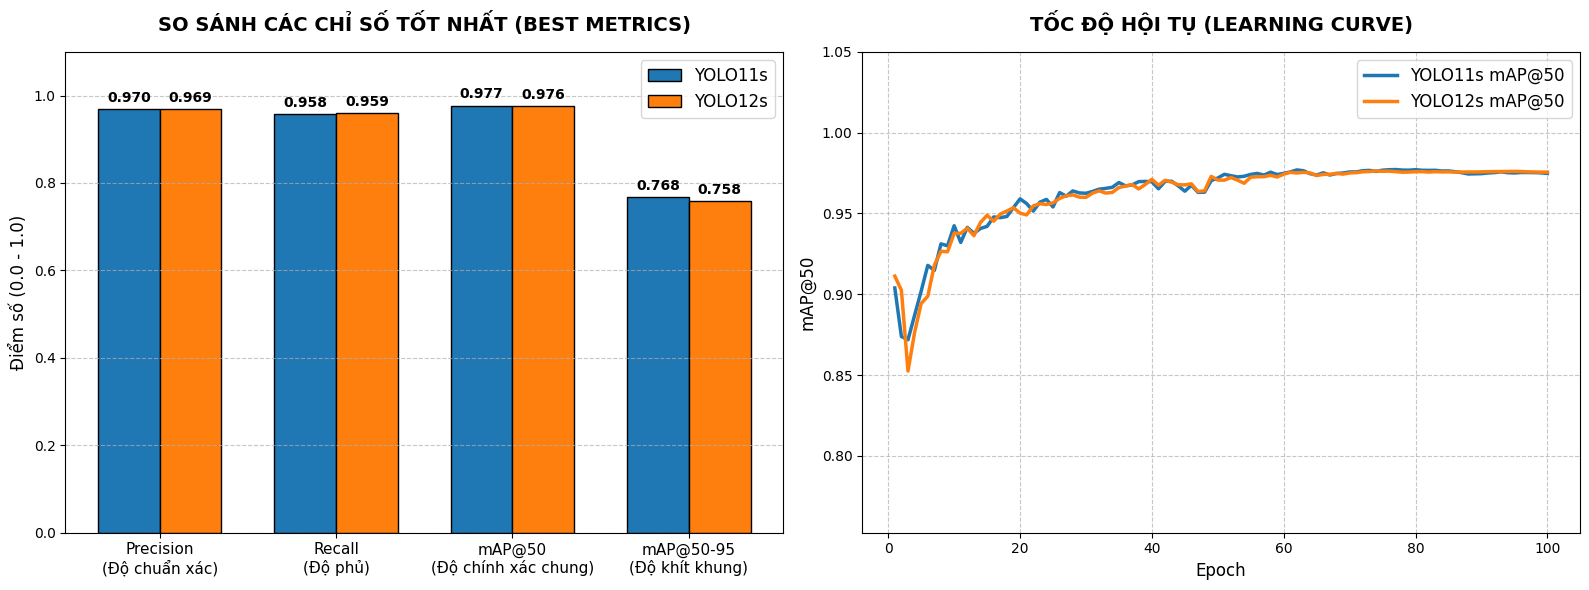

✅ Đã lưu biểu đồ so sánh tại: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\model_comparison_chart.png

📊 BẢNG TÓM TẮT:
🥇 YOLO11s: mAP50 = 0.9772 (Đạt đỉnh tại Epoch 77)
🥇 YOLO12s: mAP50 = 0.9763 (Đạt đỉnh tại Epoch 74)


In [76]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# =============================================================================
# CELL: SO SÁNH HIỆU NĂNG 2 MÔ HÌNH YOLO
# =============================================================================

print("="*80)
print("TIẾN HÀNH ĐỌC LOG VÀ VẼ BIỂU ĐỒ SO SÁNH")
print("="*80)

# ---------------------------------------------------------
# 1. CẤU HÌNH ĐƯỜNG DẪN ĐẾN FILE RESULTS.CSV
# Thay đổi OUTPUT_DATASET_PATH cho đúng với thư mục của bạn
# ---------------------------------------------------------
OUTPUT_DATASET_PATH = r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection"

# Đường dẫn tới file log của 2 model (dựa theo code trước đó)
csv_model_1 = os.path.join(OUTPUT_DATASET_PATH, 'trained_models_yolo11s', 'training_logs', 'results.csv')
csv_model_2 = os.path.join(OUTPUT_DATASET_PATH, 'trained_models_yolo12s', 'training_logs', 'results.csv')

name_1 = "YOLO11s"
name_2 = "YOLO12s"

# Hàm đọc và làm sạch dữ liệu CSV
def load_and_clean_csv(csv_path):
    if not os.path.exists(csv_path):
        print(f"❌ Không tìm thấy file: {csv_path}")
        return None
    df = pd.read_csv(csv_path)
    # Xóa khoảng trắng thừa ở tên cột do Ultralytics sinh ra
    df.columns = df.columns.str.strip()
    return df

df1 = load_and_clean_csv(csv_model_1)
df2 = load_and_clean_csv(csv_model_2)

if df1 is not None and df2 is not None:
    # Các cột dữ liệu cần quan tâm
    col_epoch = 'epoch'
    col_map50 = 'metrics/mAP50(B)'
    col_map50_95 = 'metrics/mAP50-95(B)'
    col_precision = 'metrics/precision(B)'
    col_recall = 'metrics/recall(B)'
    
    # Lấy các chỉ số TỐT NHẤT (dựa trên max mAP50)
    best_idx1 = df1[col_map50].idxmax()
    best_idx2 = df2[col_map50].idxmax()
    
    metrics_1 = [df1.loc[best_idx1, col_precision], df1.loc[best_idx1, col_recall], 
                 df1.loc[best_idx1, col_map50], df1.loc[best_idx1, col_map50_95]]
    metrics_2 = [df2.loc[best_idx2, col_precision], df2.loc[best_idx2, col_recall], 
                 df2.loc[best_idx2, col_map50], df2.loc[best_idx2, col_map50_95]]
    
    labels = ['Precision\n(Độ chuẩn xác)', 'Recall\n(Độ phủ)', 'mAP@50\n(Độ chính xác chung)', 'mAP@50-95\n(Độ khít khung)']
    
    # ---------------------------------------------------------
    # 2. VẼ BIỂU ĐỒ SO SÁNH (FIGURE CHÍNH)
    # ---------------------------------------------------------
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    # ---- BIỂU ĐỒ 1: SO SÁNH CHỈ SỐ CAO NHẤT (BAR CHART) ----
    x = np.arange(len(labels))
    width = 0.35
    
    rects1 = ax1.bar(x - width/2, metrics_1, width, label=name_1, color='#1f77b4', edgecolor='black')
    rects2 = ax1.bar(x + width/2, metrics_2, width, label=name_2, color='#ff7f0e', edgecolor='black')
    
    ax1.set_ylabel('Điểm số (0.0 - 1.0)', fontsize=12)
    ax1.set_title('SO SÁNH CÁC CHỈ SỐ TỐT NHẤT (BEST METRICS)', fontsize=14, fontweight='bold', pad=15)
    ax1.set_xticks(x)
    ax1.set_xticklabels(labels, fontsize=11)
    ax1.set_ylim(0, 1.1)
    ax1.legend(fontsize=12)
    ax1.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Thêm số liệu lên đỉnh cột
    def autolabel(rects, ax):
        for rect in rects:
            height = rect.get_height()
            ax.annotate(f'{height:.3f}',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 3),  # 3 points vertical offset
                        textcoords="offset points",
                        ha='center', va='bottom', fontweight='bold')
    
    autolabel(rects1, ax1)
    autolabel(rects2, ax1)
    
    # ---- BIỂU ĐỒ 2: TIẾN ĐỘ HỌC - TỐC ĐỘ HỘI TỤ (LINE CHART) ----
    ax2.plot(df1[col_epoch], df1[col_map50], label=f'{name_1} mAP@50', color='#1f77b4', linewidth=2.5)
    ax2.plot(df2[col_epoch], df2[col_map50], label=f'{name_2} mAP@50', color='#ff7f0e', linewidth=2.5)
    
    ax2.set_xlabel('Epoch', fontsize=12)
    ax2.set_ylabel('mAP@50', fontsize=12)
    ax2.set_title('TỐC ĐỘ HỘI TỤ (LEARNING CURVE)', fontsize=14, fontweight='bold', pad=15)
    ax2.legend(fontsize=12)
    ax2.grid(True, linestyle='--', alpha=0.7)
    ax2.set_ylim(max(0, min(df1[col_map50].min(), df2[col_map50].min()) - 0.1), 1.05)
    
    plt.tight_layout()
    
    # Lưu biểu đồ
    save_path = os.path.join(OUTPUT_DATASET_PATH, 'model_comparison_chart.png')
    plt.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.show()
    
    print(f"✅ Đã lưu biểu đồ so sánh tại: {save_path}")
    print("\n📊 BẢNG TÓM TẮT:")
    print(f"🥇 {name_1}: mAP50 = {df1.loc[best_idx1, col_map50]:.4f} (Đạt đỉnh tại Epoch {best_idx1+1})")
    print(f"🥇 {name_2}: mAP50 = {df2.loc[best_idx2, col_map50]:.4f} (Đạt đỉnh tại Epoch {best_idx2+1})")

## Demo

### Yolo11s

#### Anh

🚀 Đang tải YOLO11s và nhận diện với Conf = 0.5...

0: 640x640 3 Barcodes, 11.7ms
1: 640x640 2 Barcodes, 11.7ms
2: 640x640 2 Barcodes, 11.7ms
3: 640x640 4 Barcodes, 11.7ms
4: 640x640 2 Barcodes, 11.7ms
5: 640x640 1 Barcode, 11.7ms
6: 640x640 1 QR Code, 11.7ms
7: 640x640 1 QR Code, 11.7ms
Speed: 4.0ms preprocess, 11.7ms inference, 2.1ms postprocess per image at shape (1, 3, 640, 640)
💾 Đã lưu: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\KetQua11s\result_1.jpg
💾 Đã lưu: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\KetQua11s\result_2.jpg
💾 Đã lưu: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\KetQua11s\result_3.jpg
💾 Đã lưu: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\KetQua11s\result_4.jpg
💾 Đã lưu: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\KetQua11s\result_5.jpg
💾 Đã lưu: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\KetQua11s\result_6.jpg
💾 Đã lưu: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\KetQua11s\result_7.jpg

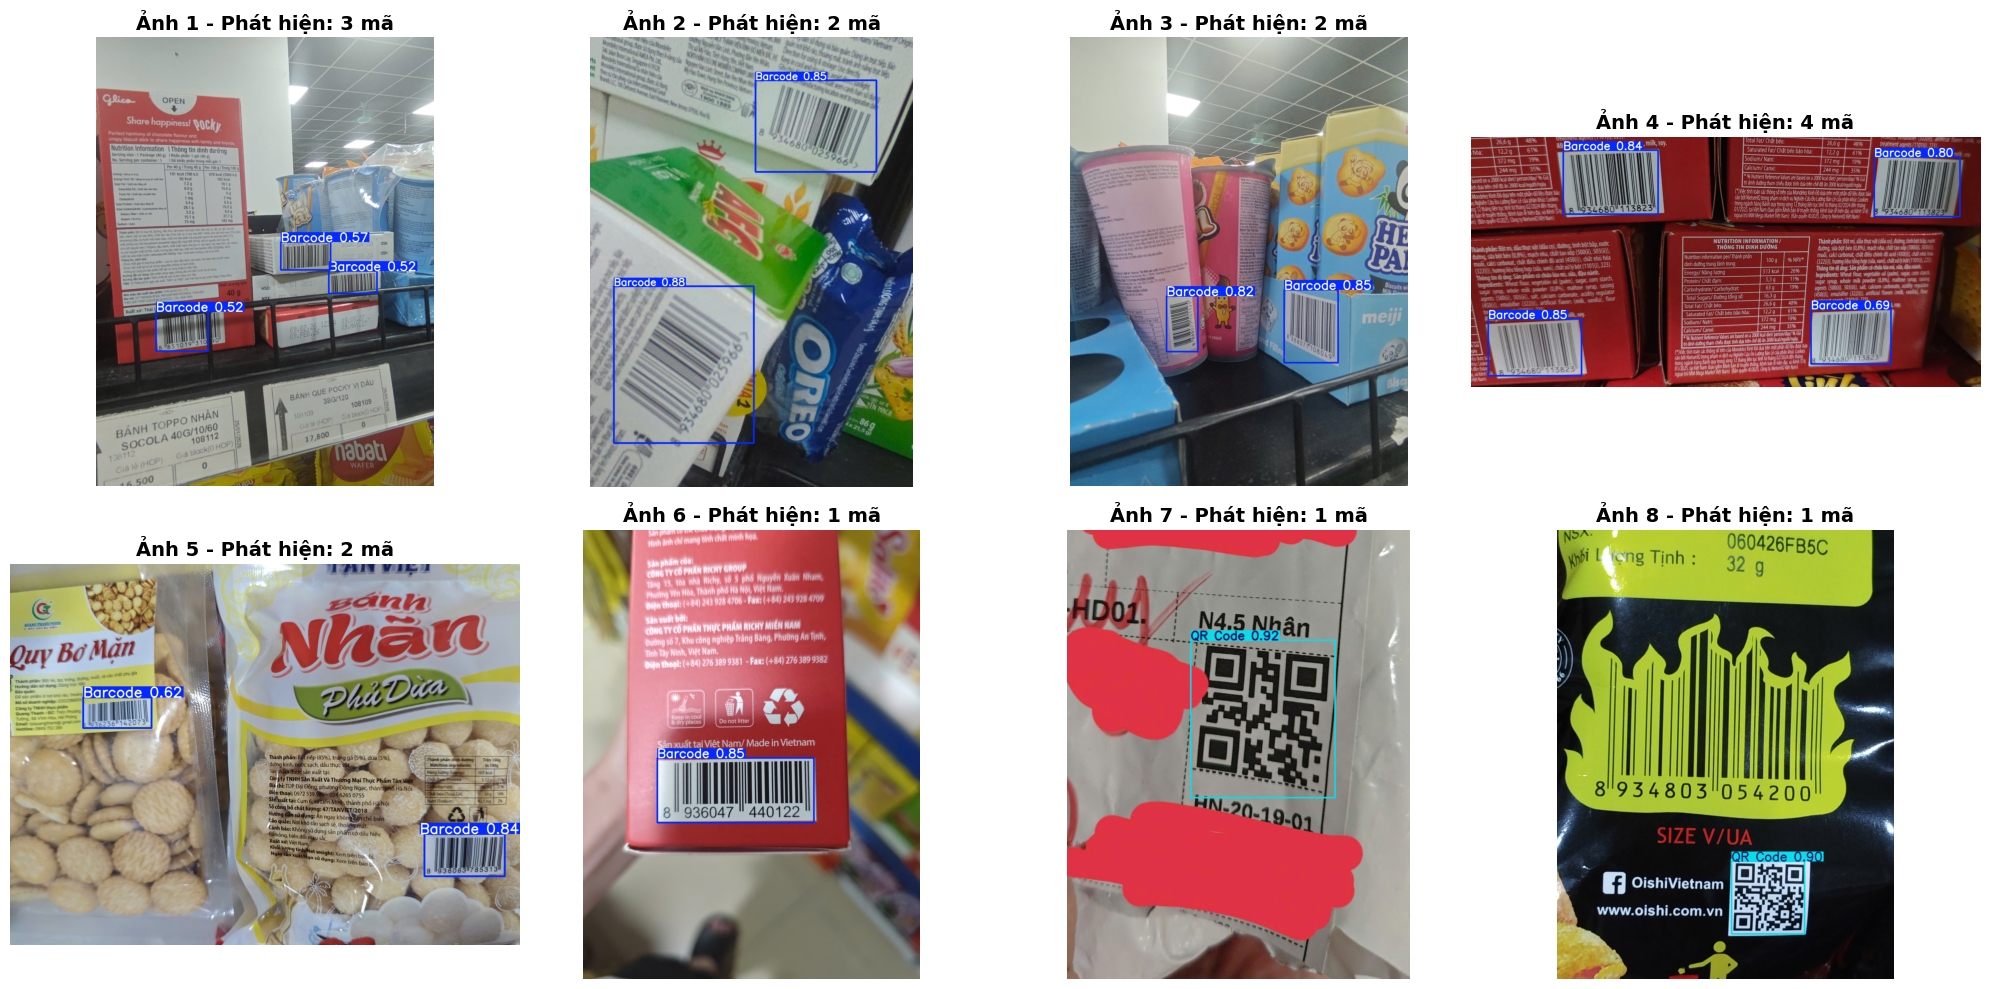


✅ Hoàn tất! Tất cả ảnh kết quả đã được lưu tại: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\KetQua11s


In [115]:
import os
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# =============================================================================
# DEMO YOLO11s: NHẬN DIỆN VÀ LƯU ẢNH KẾT QUẢ (HIỂN THỊ KHUNG 2x4)
# =============================================================================

# 1. CẤU HÌNH PARAMETERS
MODEL_PATH = r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\trained_models_yolo11s\best.pt"
CONF_THRESH = 0.50  # Ngưỡng tin cậy

# Thư mục chứa ảnh gốc (8 ảnh)
IMG_PATHS = [
    r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Anh\1.jpg", 
    r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Anh\2.jpg",
    r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Anh\3.jpg",
    r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Anh\4.jpg", 
    r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Anh\5.jpg",
    r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Anh\6.jpg",
    r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Anh\7.jpg",
    r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Anh\8.jpg"
]

# Thư mục để lưu ảnh kết quả
SAVE_DIR = r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\KetQua11s"
os.makedirs(SAVE_DIR, exist_ok=True) # Tạo thư mục nếu chưa có

# 2. LOAD MÔ HÌNH VÀ PREDICT
print(f"🚀 Đang tải YOLO11s và nhận diện với Conf = {CONF_THRESH}...")
model = YOLO(MODEL_PATH)
results = model.predict(source=IMG_PATHS, conf=CONF_THRESH)

# 3. VẼ VÀ LƯU KẾT QUẢ
# (CHỈNH SỬA Ở ĐÂY): Tạo lưới 2 hàng x 4 cột. Điều chỉnh figsize=(20, 10) để khung hình rộng rãi hơn.
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

# Dàn phẳng mảng axes 2D thành 1D để lặp dễ dàng
axes = axes.flatten()

for i, r in enumerate(results):
    # Lấy mảng pixel đã vẽ khung (dạng BGR)
    img_bgr = r.plot()
    
    # Lưu ảnh vào thư mục đích
    save_path = os.path.join(SAVE_DIR, f"result_{i+1}.jpg")
    cv2.imwrite(save_path, img_bgr)
    print(f"💾 Đã lưu: {save_path}")
    
    # Hiển thị lên màn hình (Chuyển BGR sang RGB để Matplotlib hiển thị đúng màu)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    # Đưa ảnh vào đúng ô trong lưới
    axes[i].imshow(img_rgb)
    axes[i].axis('off')
    axes[i].set_title(f"Ảnh {i+1} - Phát hiện: {len(r.boxes)} mã", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"\n✅ Hoàn tất! Tất cả ảnh kết quả đã được lưu tại: {SAVE_DIR}")

#### Video

In [86]:
import os
from ultralytics import YOLO

# =============================================================================
# DEMO YOLO11s: NHẬN DIỆN TRÊN 1 VIDEO
# =============================================================================

# 1. CẤU HÌNH PARAMETERS
MODEL_PATH = r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\trained_models_yolo11s\best.pt"
CONF_THRESH = 0.45  # Thường khi chạy video, ngưỡng để thấp hơn ảnh tĩnh 1 chút (vd: 0.45)

# Thay bằng đường dẫn video thật của bạn
VIDEO_PATH = r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Video\test.mp4" 

# Đường dẫn thư mục sẽ xuất video kết quả ra
SAVE_DIR = r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Video"
OUTPUT_FOLDER_NAME = "yolo11s_video"

# 2. CHẠY INFERENCE
print(f"🎬 Đang xử lý video bằng YOLO11s... (Vui lòng đợi)")
model = YOLO(MODEL_PATH)

# stream=True giúp tối ưu RAM, không tải toàn bộ video lên RAM cùng lúc
results = model.predict(
    source=VIDEO_PATH,
    conf=CONF_THRESH,
    save=True,              # Yêu cầu Ultralytics lưu lại thành video .avi hoặc .mp4
    project=SAVE_DIR,       
    name=OUTPUT_FOLDER_NAME,
    exist_ok=True,
    stream=True             
)

# Chạy vòng lặp để kích hoạt Generator xử lý từng frame
for r in results:
    pass

print(f"✅ XỬ LÝ HOÀN TẤT!")
print(f"📁 Video kết quả đã được lưu tại: {os.path.join(SAVE_DIR, OUTPUT_FOLDER_NAME)}")

🎬 Đang xử lý video bằng YOLO11s... (Vui lòng đợi)

video 1/1 (frame 1/2222) D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Video\test.mp4: 640x384 (no detections), 11.7ms
video 1/1 (frame 2/2222) D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Video\test.mp4: 640x384 1 Barcode, 12.5ms
video 1/1 (frame 3/2222) D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Video\test.mp4: 640x384 1 Barcode, 11.9ms
video 1/1 (frame 4/2222) D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Video\test.mp4: 640x384 1 Barcode, 12.9ms
video 1/1 (frame 5/2222) D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Video\test.mp4: 640x384 1 Barcode, 13.8ms
video 1/1 (frame 6/2222) D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Video\test.mp4: 640x384 1 Barcode, 12.9ms
video 1/1 (frame 7/2222) D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Video\test.mp4: 640x384 1 Barcode, 11.3ms
video 1/1 (frame 8/2222) D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Video\tes

### Yolo12s

#### Anh

🚀 Đang tải YOLO11s và nhận diện với Conf = 0.45...

0: 640x640 3 Barcodes, 56.4ms
1: 640x640 2 Barcodes, 56.4ms
2: 640x640 2 Barcodes, 56.4ms
3: 640x640 4 Barcodes, 56.4ms
4: 640x640 2 Barcodes, 56.4ms
5: 640x640 1 Barcode, 56.4ms
6: 640x640 1 QR Code, 56.4ms
7: 640x640 1 Barcode, 1 QR Code, 56.4ms
Speed: 3.4ms preprocess, 56.4ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 640)
💾 Đã lưu: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\KetQua12s\result_1.jpg
💾 Đã lưu: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\KetQua12s\result_2.jpg
💾 Đã lưu: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\KetQua12s\result_3.jpg
💾 Đã lưu: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\KetQua12s\result_4.jpg
💾 Đã lưu: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\KetQua12s\result_5.jpg
💾 Đã lưu: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\KetQua12s\result_6.jpg
💾 Đã lưu: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\KetQua12s\

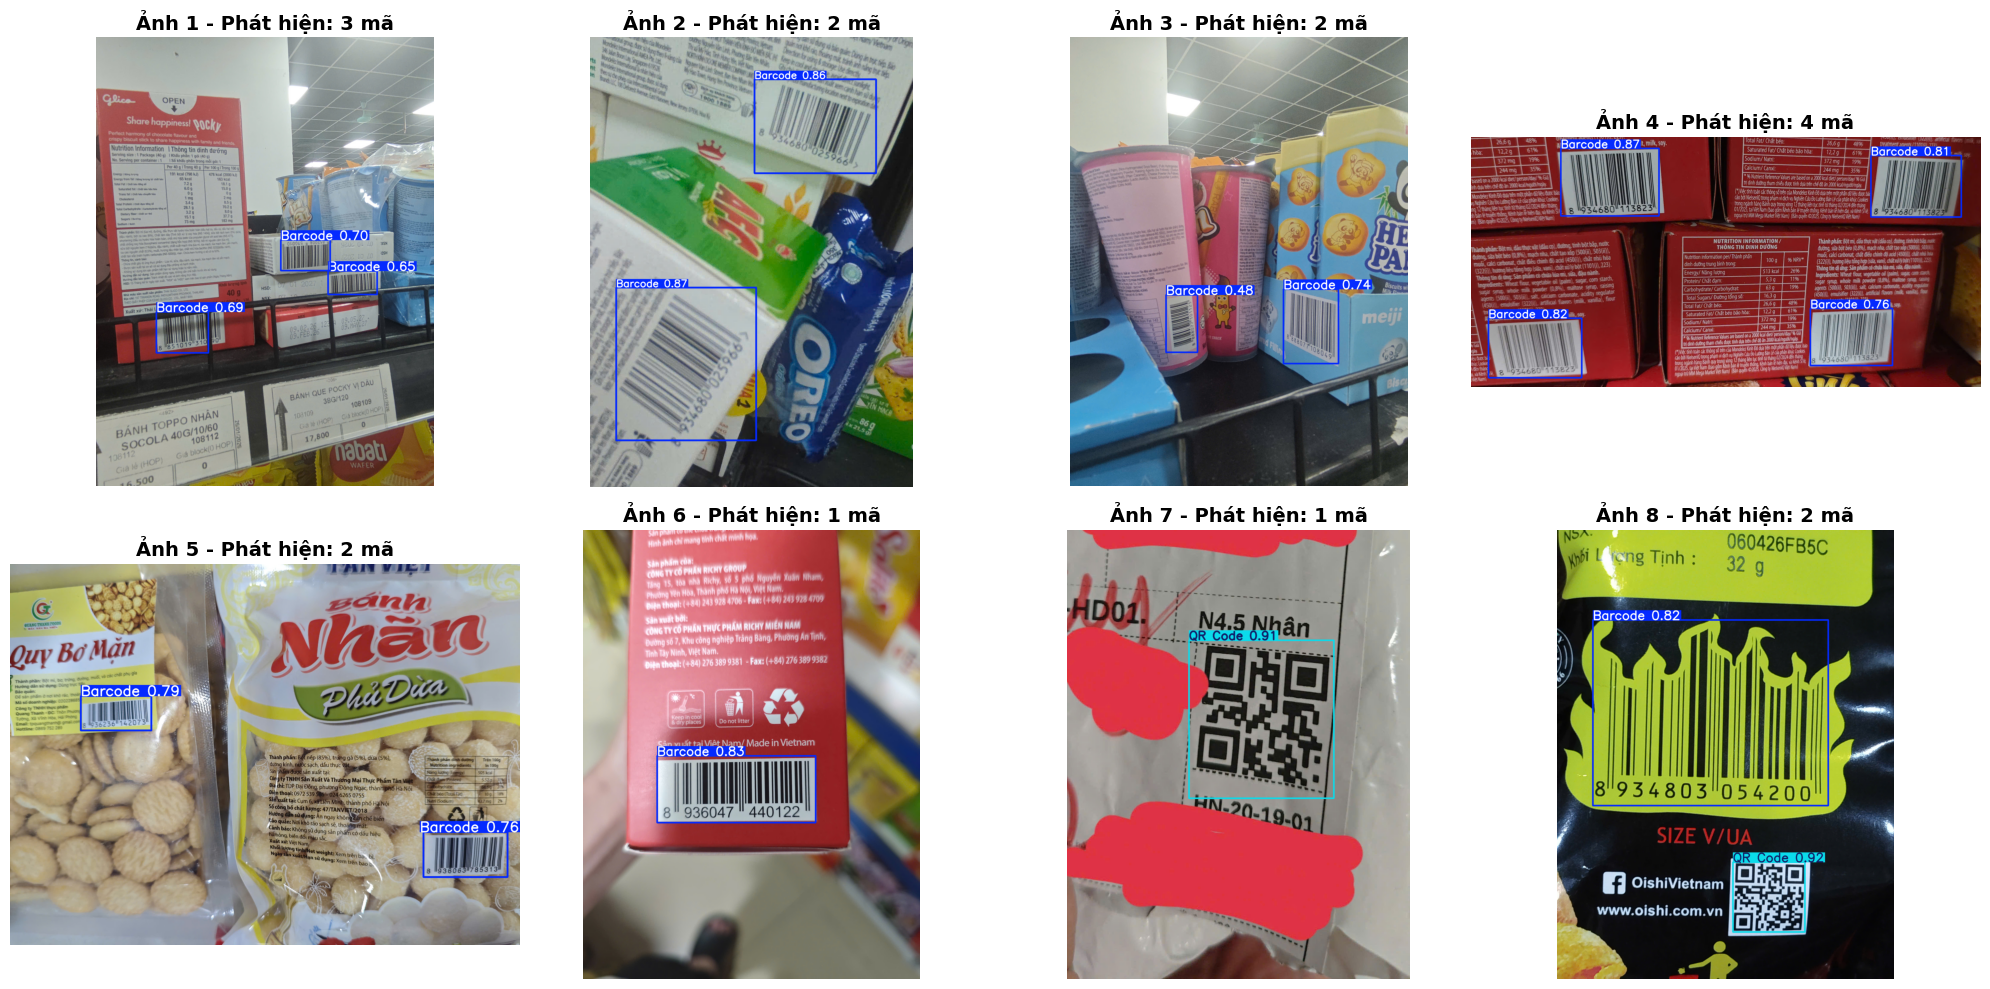


✅ Hoàn tất! Tất cả ảnh kết quả đã được lưu tại: D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\KetQua12s


In [117]:
import os
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# =============================================================================
# DEMO YOLO11s: NHẬN DIỆN VÀ LƯU ẢNH KẾT QUẢ (HIỂN THỊ KHUNG 2x4)
# =============================================================================

# 1. CẤU HÌNH PARAMETERS
MODEL_PATH = r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\trained_models_yolo12s\best.pt"
CONF_THRESH = 0.45  # Ngưỡng tin cậy

# Thư mục chứa ảnh gốc (8 ảnh)
IMG_PATHS = [
    r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Anh\1.jpg", 
    r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Anh\2.jpg",
    r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Anh\3.jpg",
    r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Anh\4.jpg", 
    r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Anh\5.jpg",
    r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Anh\6.jpg",
    r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Anh\7.jpg",
    r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Anh\8.jpg"
]

# Thư mục để lưu ảnh kết quả
SAVE_DIR = r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\KetQua12s"
os.makedirs(SAVE_DIR, exist_ok=True) # Tạo thư mục nếu chưa có

# 2. LOAD MÔ HÌNH VÀ PREDICT
print(f"🚀 Đang tải YOLO11s và nhận diện với Conf = {CONF_THRESH}...")
model = YOLO(MODEL_PATH)
results = model.predict(source=IMG_PATHS, conf=CONF_THRESH)

# 3. VẼ VÀ LƯU KẾT QUẢ
# (CHỈNH SỬA Ở ĐÂY): Tạo lưới 2 hàng x 4 cột. Điều chỉnh figsize=(20, 10) để khung hình rộng rãi hơn.
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

# Dàn phẳng mảng axes 2D thành 1D để lặp dễ dàng
axes = axes.flatten()

for i, r in enumerate(results):
    # Lấy mảng pixel đã vẽ khung (dạng BGR)
    img_bgr = r.plot()
    
    # Lưu ảnh vào thư mục đích
    save_path = os.path.join(SAVE_DIR, f"result_{i+1}.jpg")
    cv2.imwrite(save_path, img_bgr)
    print(f"💾 Đã lưu: {save_path}")
    
    # Hiển thị lên màn hình (Chuyển BGR sang RGB để Matplotlib hiển thị đúng màu)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    # Đưa ảnh vào đúng ô trong lưới
    axes[i].imshow(img_rgb)
    axes[i].axis('off')
    axes[i].set_title(f"Ảnh {i+1} - Phát hiện: {len(r.boxes)} mã", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"\n✅ Hoàn tất! Tất cả ảnh kết quả đã được lưu tại: {SAVE_DIR}")

#### Video

In [89]:
import os
from ultralytics import YOLO

# =============================================================================
# DEMO YOLO12s: NHẬN DIỆN TRÊN 1 VIDEO
# =============================================================================

# 1. CẤU HÌNH PARAMETERS
MODEL_PATH = r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\trained_models_yolo12s\best.pt"
CONF_THRESH = 0.45  # Ngưỡng tin cậy

# Thay bằng đường dẫn video thật của bạn
VIDEO_PATH = r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Video\test.mp4" 

# Đường dẫn thư mục sẽ xuất video kết quả ra
SAVE_DIR = r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Video"
OUTPUT_FOLDER_NAME = "yolo12s_video"

# 2. CHẠY INFERENCE
print(f"🎬 Đang xử lý video bằng YOLO12s... (Vui lòng đợi)")
model = YOLO(MODEL_PATH)

results = model.predict(
    source=VIDEO_PATH,
    conf=CONF_THRESH,
    save=True,              
    project=SAVE_DIR,       
    name=OUTPUT_FOLDER_NAME,
    exist_ok=True,
    stream=True             
)

for r in results:
    pass

print(f"✅ XỬ LÝ HOÀN TẤT!")
print(f"📁 Video kết quả đã được lưu tại: {os.path.join(SAVE_DIR, OUTPUT_FOLDER_NAME)}")

🎬 Đang xử lý video bằng YOLO12s... (Vui lòng đợi)

video 1/1 (frame 1/2222) D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Video\test.mp4: 640x384 (no detections), 21.0ms
video 1/1 (frame 2/2222) D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Video\test.mp4: 640x384 1 Barcode, 17.8ms
video 1/1 (frame 3/2222) D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Video\test.mp4: 640x384 1 Barcode, 21.8ms
video 1/1 (frame 4/2222) D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Video\test.mp4: 640x384 1 Barcode, 14.1ms
video 1/1 (frame 5/2222) D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Video\test.mp4: 640x384 1 Barcode, 15.8ms
video 1/1 (frame 6/2222) D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Video\test.mp4: 640x384 1 Barcode, 12.2ms
video 1/1 (frame 7/2222) D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Video\test.mp4: 640x384 1 Barcode, 29.9ms
video 1/1 (frame 8/2222) D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\ObjectDetection\DEMO\Video\tes

In [1]:
import cv2
import os

def extract_frames(video_path, output_dir, frame_interval=15):
    # Tạo thư mục lưu ảnh nếu chưa tồn tại
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)

    # Khởi tạo đối tượng đọc video
    cap = cv2.VideoCapture(video_path)
    
    if not cap.isOpened():
        print("Lỗi: Không thể mở video. Vui lòng kiểm tra lại đường dẫn.")
        return

    # Trích xuất thông số của video
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    
    print(f"Thông tin video: {fps} FPS, Tổng số {total_frames} frames.")
    print(f"Trích xuất 1 ảnh sau mỗi {frame_interval} frames...")

    frame_count = 0
    saved_count = 0

    while True:
        success, frame = cap.read()
        
        # Thoát vòng lặp khi video kết thúc
        if not success:
            break 
            
        # Chỉ lưu ảnh khi frame_count chia hết cho interval (10 hoặc 15)
        if frame_count % frame_interval == 0:
            # Format tên file với 6 chữ số (VD: frame_000015.jpg) để dễ sắp xếp
            filename = os.path.join(output_dir, f"frame_{frame_count:06d}.jpg")
            
            # Lưu ý về Video 4K: 
            # Ảnh 4K (3840x2160) tốn rất nhiều dung lượng ổ cứng và thời gian upload lên Roboflow.
            # Nếu không thực sự cần độ phân giải 4K cho bước gán nhãn, bạn có thể bỏ comment
            # dòng code dưới đây để resize ảnh xuống Full HD (1920x1080) trước khi lưu.
            # frame = cv2.resize(frame, (1920, 1080)) 
            
            cv2.imwrite(filename, frame)
            saved_count += 1
            
            # Log tiến độ ra màn hình
            if saved_count % 100 == 0:
                print(f"Đã lưu {saved_count} ảnh...")

        frame_count += 1

    # Giải phóng bộ nhớ
    cap.release()
    print(f"Hoàn thành! Đã lưu tổng cộng {saved_count} ảnh vào thư mục '{output_dir}'.")

# --- CẤU HÌNH THÔNG SỐ ĐẦU VÀO ---
if __name__ == "__main__":
    # Thay thế bằng đường dẫn thực tế tới video 13 phút của bạn
    VIDEO_PATH = "GiaoThong.mp4" 
    
    # Thư mục bạn muốn xuất ảnh ra
    OUTPUT_FOLDER = "datasetGT" 
    
    # Khoảng cách giữa các frame (Gợi ý: 30 cho video 60fps)
    INTERVAL = 30  

    extract_frames(VIDEO_PATH, OUTPUT_FOLDER, INTERVAL)

Thông tin video: 60.0 FPS, Tổng số 44247 frames.
Trích xuất 1 ảnh sau mỗi 30 frames...
Đã lưu 100 ảnh...
Đã lưu 200 ảnh...
Đã lưu 300 ảnh...
Đã lưu 400 ảnh...
Đã lưu 500 ảnh...
Đã lưu 600 ảnh...
Đã lưu 700 ảnh...
Đã lưu 800 ảnh...
Đã lưu 900 ảnh...
Đã lưu 1000 ảnh...
Đã lưu 1100 ảnh...
Đã lưu 1200 ảnh...
Đã lưu 1300 ảnh...
Đã lưu 1400 ảnh...
Hoàn thành! Đã lưu tổng cộng 1475 ảnh vào thư mục 'datasetGT'.


In [2]:
import cv2
import os
import glob

def resize_dataset(input_dir, output_dir, target_size=(1920, 1080)):
    # Tạo thư mục đầu ra nếu chưa có
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)

    # Lấy danh sách tất cả các file ảnh trong thư mục
    image_paths = glob.glob(os.path.join(input_dir, "*.jpg")) + \
                  glob.glob(os.path.join(input_dir, "*.png"))
    
    total_images = len(image_paths)
    print(f"Tìm thấy {total_images} ảnh. Bắt đầu resize xuống {target_size}...")

    count = 0
    for img_path in image_paths:
        # Đọc ảnh
        img = cv2.imread(img_path)
        if img is None:
            continue
        
        # Thay đổi kích thước
        resized_img = cv2.resize(img, target_size, interpolation=cv2.INTER_AREA)
        
        # Tạo đường dẫn lưu file mới (giữ nguyên tên gốc)
        filename = os.path.basename(img_path)
        save_path = os.path.join(output_dir, filename)
        
        # Lưu ảnh
        cv2.imwrite(save_path, resized_img)
        count += 1
        
        # In tiến độ
        if count % 500 == 0:
            print(f"Đã xử lý {count}/{total_images} ảnh...")

    print(f"Hoàn thành! Đã lưu {count} ảnh đã resize vào '{output_dir}'.")

# --- CẤU HÌNH ĐƯỜNG DẪN ---
if __name__ == "__main__":
    INPUT_FOLDER = r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\datasetGT"   # Thay bằng thư mục chứa 4783 ảnh của bạn
    OUTPUT_FOLDER = r"D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\data1920" # Thư mục chứa ảnh sau khi thu nhỏ
    
    resize_dataset(INPUT_FOLDER, OUTPUT_FOLDER)

Tìm thấy 1475 ảnh. Bắt đầu resize xuống (1920, 1080)...
Đã xử lý 500/1475 ảnh...
Đã xử lý 1000/1475 ảnh...
Hoàn thành! Đã lưu 1475 ảnh đã resize vào 'D:\Stuffs\ThiGiacMayTinh\TGMT_LAB\data1920'.
